# Transfer Learning: Cats vs. Dogs with MobileNetV2
Instead of training a CNN from scratch, reuse **MobileNetV2** pre-trained on ImageNet:

1. **Feature extraction** - freeze the pre-trained base and train only a small new classifier head.
2. **Fine-tuning** - unfreeze the top of the base and continue training with a very low learning rate.

The optimization payoff: high accuracy after a few epochs while training only a small fraction of the parameters.

Expected layout (already present in this repo, or from the Kaggle dataset `bhavikjikadara/dog-and-cat-classification-dataset`):
```
Data/
  train/       cats/ dogs/
  validation/  cats/ dogs/
```

In [1]:
import time
from pathlib import Path
import numpy as np
import matplotlib.pyplot as plt
import tensorflow as tf
from tensorflow import keras
from tensorflow.keras import layers
from tensorflow.keras.applications import MobileNetV2

keras.utils.set_random_seed(42)

DATA_DIR = Path("Data")
IMG_SIZE = 160          # MobileNetV2 supports 96-224; smaller = faster
BATCH_SIZE = 32
TRAIN_SUBSET = 4000     # images used for training; set to None to use all ~22,700 (much slower on CPU)
HEAD_EPOCHS = 3
FINE_TUNE_EPOCHS = 2

if not (DATA_DIR / "train").exists():
    raise FileNotFoundError(
        "Expected Data/train/{cats,dogs} and Data/validation/{cats,dogs}. Download with:\n"
        "  import kagglehub; kagglehub.dataset_download('bhavikjikadara/dog-and-cat-classification-dataset')\n"
        "and copy the images into that layout.")
print("GPUs:", tf.config.list_physical_devices("GPU") or "none (running on CPU)")

GPUs: none (running on CPU)


## 1. Clean the file list
Real image folders are messy. Here:
* NAS software created hidden `@eaDir` thumbnail folders inside each class folder - a recursive loader would
  silently add ~25,000 thumbnails as training images.
* Some files named `.jpg` are really BMP, GIF or Photoshop files; TensorFlow cannot decode the Photoshop ones and
  training would crash mid-epoch.

So we build the file list ourselves and check each file's header bytes.

In [2]:
# Header bytes ("magic numbers") of formats tf.io.decode_image can read
DECODABLE = (b"\xff\xd8\xff", b"\x89PNG", b"GIF8", b"BM")

def list_images(split_dir):
    paths, labels, skipped = [], [], {}
    class_names = sorted(d.name for d in split_dir.iterdir() if d.is_dir() and not d.name.startswith(("@", ".")))
    for label, class_name in enumerate(class_names):
        for path in sorted((split_dir / class_name).iterdir()):  # not recursive: skips @eaDir
            if not path.is_file():
                continue
            with open(path, "rb") as f:
                header = f.read(4)
            if header.startswith(DECODABLE):
                paths.append(str(path))
                labels.append(label)
            else:
                skipped[header] = skipped.get(header, 0) + 1
    return np.array(paths), np.array(labels), class_names, skipped

train_paths, train_labels, class_names, train_skipped = list_images(DATA_DIR / "train")
val_paths, val_labels, _, val_skipped = list_images(DATA_DIR / "validation")
print(f"Classes: {class_names}")
print(f"Train: {len(train_paths)} images (skipped {sum(train_skipped.values())}: {train_skipped})")
print(f"Validation: {len(val_paths)} images (skipped {sum(val_skipped.values())}: {val_skipped})")

if TRAIN_SUBSET:
    rng = np.random.default_rng(42)
    keep = rng.permutation(len(train_paths))[:TRAIN_SUBSET]
    train_paths, train_labels = train_paths[keep], train_labels[keep]
    print(f"Using a random subset of {len(train_paths)} training images")

Classes: ['cats', 'dogs']
Train: 22775 images (skipped 1: {b'8BPS': 1})
Validation: 2222 images (skipped 0: {})
Using a random subset of 4000 training images


In [3]:
def load_image(path, label):
    image = tf.io.decode_image(tf.io.read_file(path), channels=3, expand_animations=False)
    image = tf.image.resize(image, (IMG_SIZE, IMG_SIZE))
    return tf.cast(image, tf.uint8), label  # uint8 keeps the in-memory cache 4x smaller than float32

def make_dataset(paths, labels, shuffle):
    ds = tf.data.Dataset.from_tensor_slices((paths, labels))
    if shuffle:
        ds = ds.shuffle(len(paths), seed=42, reshuffle_each_iteration=False)
    ds = ds.map(load_image, num_parallel_calls=tf.data.AUTOTUNE).ignore_errors().cache()
    if shuffle:
        ds = ds.shuffle(1000, seed=42)
    return ds.batch(BATCH_SIZE).prefetch(tf.data.AUTOTUNE)

train_ds = make_dataset(train_paths, train_labels, shuffle=True)
val_ds = make_dataset(val_paths, val_labels, shuffle=False)

## 2. Build the model
* Augmentation layers run only during training.
* The `Rescaling` layer scales pixels to **[-1, 1]**, the range MobileNetV2 was trained with (not 0-1 via `rescale=1/255`).
* `base_model(x, training=False)` keeps the BatchNormalization layers in inference mode, which matters during fine-tuning:
  otherwise their statistics get overwritten by small batches of a new dataset.

In [4]:
base_model = MobileNetV2(weights='imagenet', include_top=False, input_shape=(IMG_SIZE, IMG_SIZE, 3))
base_model.trainable = False  # Freeze the convolutional base

augmentation = keras.Sequential([
    layers.RandomFlip("horizontal"),
    layers.RandomRotation(0.05),
    layers.RandomZoom(0.1),
], name="augmentation")

inputs = keras.Input(shape=(IMG_SIZE, IMG_SIZE, 3))
x = augmentation(inputs)
x = layers.Rescaling(1 / 127.5, offset=-1)(x)  # same as mobilenet_v2.preprocess_input: [0, 255] -> [-1, 1]
x = base_model(x, training=False)
x = layers.GlobalAveragePooling2D()(x)
x = layers.Dropout(0.2)(x)
outputs = layers.Dense(1, activation='sigmoid')(x)  # Binary classification: P(dog)
model = keras.Model(inputs, outputs)

def count_trainable(m):
    return sum(int(np.prod(w.shape)) for w in m.trainable_weights)

print(f"Total parameters:     {model.count_params():,}")
print(f"Trainable parameters: {count_trainable(model):,}  ({count_trainable(model) / model.count_params():.2%})")

Total parameters:     2,259,265
Trainable parameters: 1,281  (0.06%)


## 3. Feature extraction: train only the new head

In [5]:
model.compile(optimizer=keras.optimizers.Adam(1e-3), loss='binary_crossentropy', metrics=['accuracy'])

phases = []
start = time.perf_counter()
history = model.fit(train_ds, epochs=HEAD_EPOCHS, validation_data=val_ds, verbose=2)
phases.append({"phase": "head only", "trainable_params": count_trainable(model),
               "val_accuracy": history.history['val_accuracy'][-1], "train_time_s": time.perf_counter() - start})

Epoch 1/3


125/125 - 38s - 300ms/step - accuracy: 0.9222 - loss: 0.1956 - val_accuracy: 0.9685 - val_loss: 0.0897


Epoch 2/3


125/125 - 33s - 263ms/step - accuracy: 0.9630 - loss: 0.0937 - val_accuracy: 0.9761 - val_loss: 0.0636


Epoch 3/3


125/125 - 33s - 263ms/step - accuracy: 0.9705 - loss: 0.0811 - val_accuracy: 0.9775 - val_loss: 0.0558


## 4. Fine-tuning: unfreeze the top of the base model

In [6]:
base_model.trainable = True
unfreeze_at = 100  # MobileNetV2 has 154 layers; keep the first 100 (generic edge/texture features) frozen
for layer in base_model.layers[:unfreeze_at]:
    layer.trainable = False

# Recompile after changing trainable flags; use a much lower learning rate so pre-trained weights change gently
model.compile(optimizer=keras.optimizers.Adam(1e-5), loss='binary_crossentropy', metrics=['accuracy'])
print(f"Trainable parameters now: {count_trainable(model):,}")

start = time.perf_counter()
history_fine = model.fit(train_ds, epochs=HEAD_EPOCHS + FINE_TUNE_EPOCHS, initial_epoch=HEAD_EPOCHS,
                         validation_data=val_ds, verbose=2)
phases.append({"phase": "fine-tuned", "trainable_params": count_trainable(model),
               "val_accuracy": history_fine.history['val_accuracy'][-1], "train_time_s": time.perf_counter() - start})
print("Training complete!")

Trainable parameters now: 1,862,721
Epoch 4/5


125/125 - 55s - 441ms/step - accuracy: 0.9007 - loss: 0.2260 - val_accuracy: 0.9775 - val_loss: 0.0661


Epoch 5/5


125/125 - 47s - 373ms/step - accuracy: 0.9472 - loss: 0.1334 - val_accuracy: 0.9797 - val_loss: 0.0602


Training complete!


## 5. Evaluate

            trainable_params  val_accuracy  train_time_s
phase                                                   
head only               1281         0.977       103.184
fine-tuned           1862721         0.980       101.838

Confusion Matrix (rows = true ['cats', 'dogs']):
[[1072   39]
 [   6 1105]]
              precision    recall  f1-score   support

        cats      0.994     0.965     0.979      1111
        dogs      0.966     0.995     0.980      1111

    accuracy                          0.980      2222
   macro avg      0.980     0.980     0.980      2222
weighted avg      0.980     0.980     0.980      2222



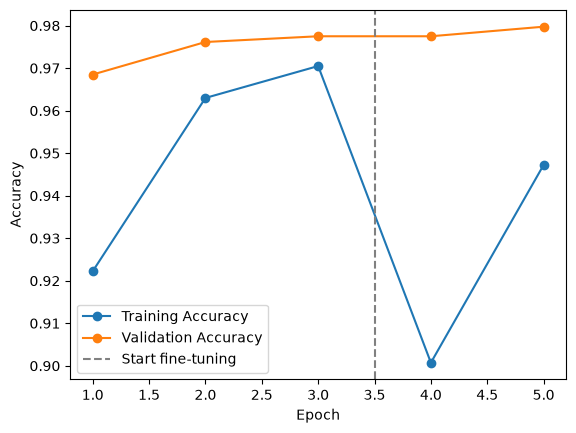

In [7]:
import pandas as pd
from sklearn.metrics import classification_report, confusion_matrix

y_true = np.concatenate([y for _, y in val_ds])
y_prob = model.predict(val_ds, verbose=0).ravel()
y_pred = (y_prob >= 0.5).astype(int)

print(pd.DataFrame(phases).set_index("phase").round(3).to_string())
print(f"\nConfusion Matrix (rows = true {class_names}):\n{confusion_matrix(y_true, y_pred)}")
print(classification_report(y_true, y_pred, target_names=class_names, digits=3))

acc = history.history['accuracy'] + history_fine.history['accuracy']
val_acc = history.history['val_accuracy'] + history_fine.history['val_accuracy']
plt.plot(range(1, len(acc) + 1), acc, 'o-', label='Training Accuracy')
plt.plot(range(1, len(val_acc) + 1), val_acc, 'o-', label='Validation Accuracy')
plt.axvline(HEAD_EPOCHS + 0.5, color='gray', linestyle='--', label='Start fine-tuning')
plt.xlabel('Epoch')
plt.ylabel('Accuracy')
plt.legend()
plt.show()

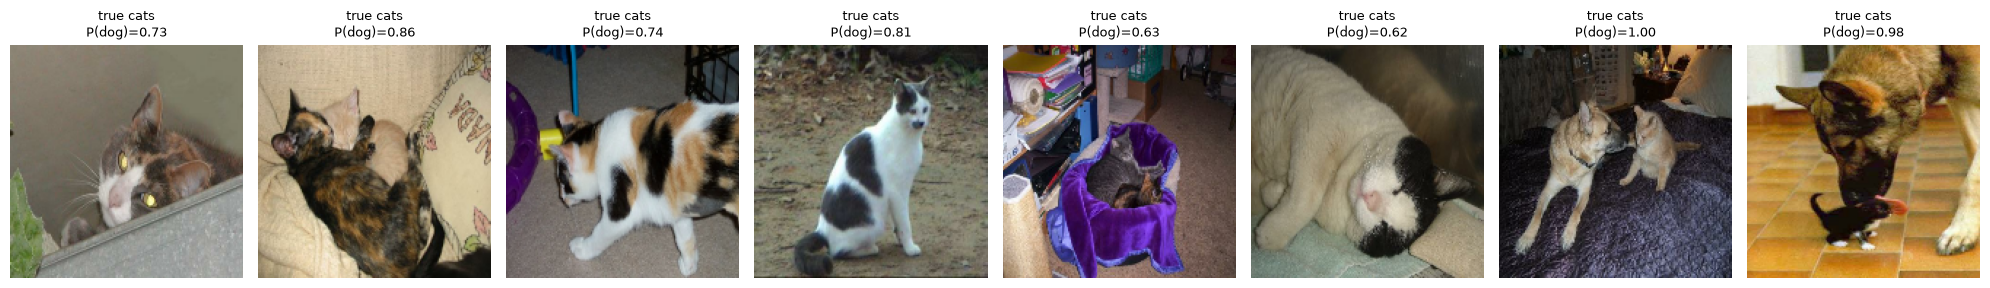

In [8]:
# Look at the mistakes - often ambiguous, mislabeled, or unusual images
images = np.concatenate([x for x, _ in val_ds])
wrong = np.flatnonzero(y_pred != y_true)[:8]
fig, axes = plt.subplots(1, max(len(wrong), 1), figsize=(2.5 * max(len(wrong), 1), 3), squeeze=False)
for ax, i in zip(axes[0], wrong):
    ax.imshow(images[i])
    ax.set_title(f"true {class_names[y_true[i]]}\nP(dog)={y_prob[i]:.2f}", fontsize=9)
    ax.axis('off')
plt.tight_layout()
plt.show()